# Extractor evaluation: eacr-2026

LLM-as-judge results for `data/output/eacr-2026.jsonl`, read from `eval.jsonl` in this folder.
Plots are saved to `data/plots/step2/`. Run with the repo's uv environment (`uv run jupyter lab step2/eval.ipynb` from `ecc1/`).

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PLOT_DIR = ROOT / "data" / "plots" / "step2"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

ev = json.loads((ROOT / "step2" / "eval.jsonl").read_text().splitlines()[0])
talks, fields = ev["talks"], ev["fields"]

INK, MUTED = "#1f2937", "#6b7280"
BLUE, LIGHT = "#2563eb", "#93c5fd"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.labelsize": 11,
        "axes.labelcolor": MUTED,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 11,
        "xtick.color": MUTED,
        "ytick.color": INK,
        "text.color": INK,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.fontsize": 10.5,
        "legend.frameon": False,
        "figure.dpi": 110,
        "savefig.dpi": 200,
    },
)


def finish(fig, name):
    sns.despine(fig=fig, left=True)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


print(ev["conference"], "|", ev["conference_url"])
print(f"macro F1 = {ev['macro_f1']} (skipped: {', '.join(ev['macro_f1_skipped_fields']) or 'none'})")
print("Saving plots to", PLOT_DIR)

eacr-2026 | https://dashboard.eacr.org/eacr26/program/08-jun
macro F1 = 0.867 (skipped: extra_url)
Saving plots to /Users/emlacic/test/recsys/ecc1/data/plots/step2


## 1. Talk level

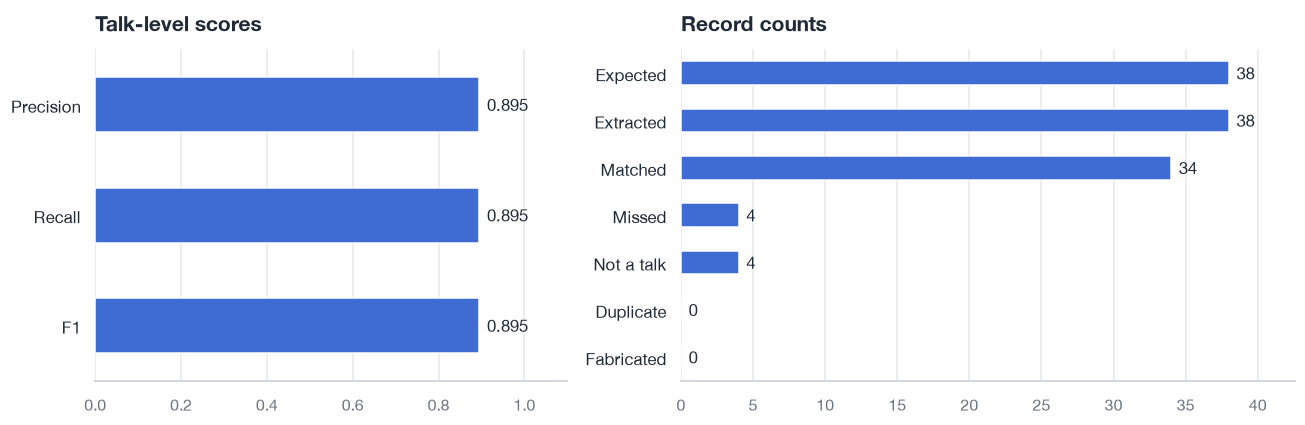

In [4]:
scores = pd.DataFrame({"metric": ["Precision", "Recall", "F1"],
                       "value": [talks["precision"], talks["recall"], talks["f1"]]})
counts = pd.DataFrame({
    "record": ["Expected", "Extracted", "Matched", "Missed", "Not a talk", "Duplicate", "Fabricated"],
    "count": [talks[k] for k in ["expected", "extracted", "matched", "missed", "not_a_talk", "duplicate", "fabricated"]],
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.3]})

sns.barplot(data=scores, x="value", y="metric", color=BLUE, width=0.5, ax=ax1)
ax1.bar_label(ax1.containers[0], labels=[f"{v:.3f}" for v in scores["value"]], padding=5, fontsize=11)
ax1.set(xlim=(0, 1.1), xlabel="", ylabel="", title="Talk-level scores")

sns.barplot(data=counts, x="count", y="record", color=BLUE, width=0.5, ax=ax2)
ax2.bar_label(ax2.containers[0], padding=5, fontsize=11)
ax2.set(xlim=(0, counts["count"].max() * 1.12), xlabel="", ylabel="", title="Record counts")

finish(fig, "01_talk_level")

## 2. Field-level F1

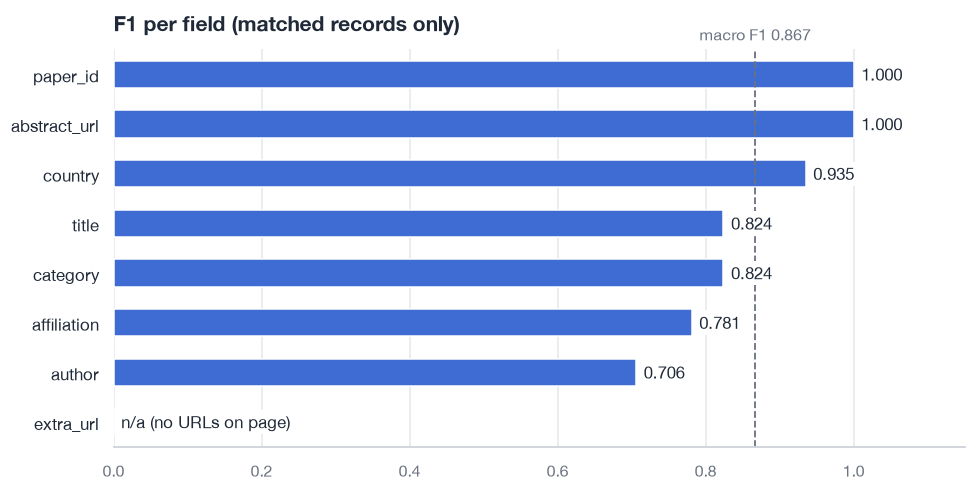

In [5]:
order = sorted(fields, key=lambda f: (fields[f]["f1"] is None, -(fields[f]["f1"] or 0)))
f1 = pd.DataFrame({"field": order, "f1": [fields[f]["f1"] for f in order]})
labels = ["n/a (no URLs on page)" if pd.isna(v) else f"{v:.3f}" for v in f1["f1"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(data=f1.fillna({"f1": 0}), x="f1", y="field", color=BLUE, width=0.55, ax=ax)
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontsize=11,
             bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.axvline(ev["macro_f1"], color=MUTED, linestyle="--", linewidth=1.2)
ax.annotate(f"macro F1 {ev['macro_f1']:.3f}", (ev["macro_f1"], 1), xycoords=("data", "axes fraction"),
            xytext=(0, 6), textcoords="offset points", ha="center", color=MUTED, fontsize=10.5)
ax.set(xlim=(0, 1.15), xlabel="", ylabel="", title="F1 per field (matched records only)")
ax.title.set_position((0, 1.08))

finish(fig, "02_field_f1")

## 3. Precision vs recall per field

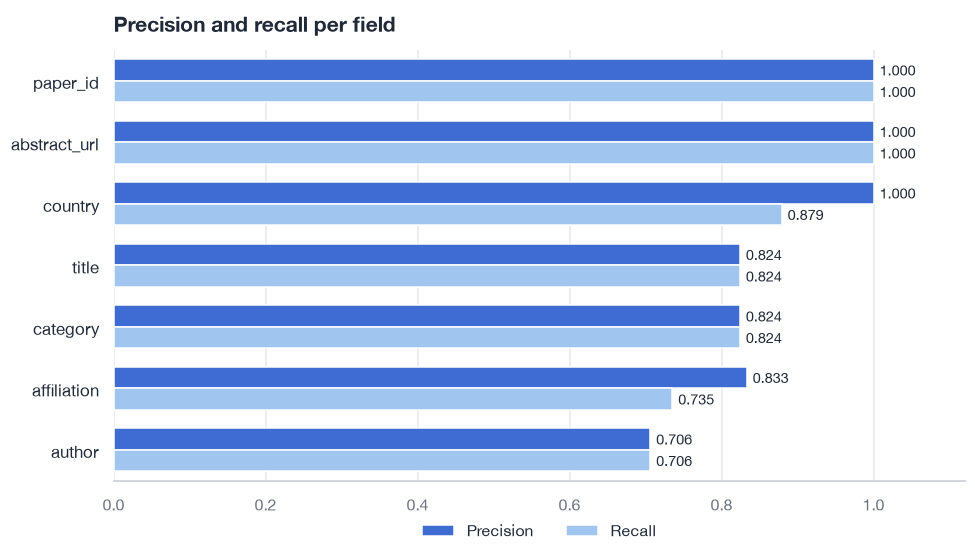

In [6]:
pr = pd.DataFrame(
    [(f, m.capitalize(), fields[f][m]) for f in order if fields[f]["f1"] is not None
     for m in ("precision", "recall")],
    columns=["field", "metric", "value"],
)

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.barplot(data=pr, x="value", y="field", hue="metric", palette=[BLUE, LIGHT], width=0.7, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=4, fontsize=9.5)
ax.set(xlim=(0, 1.12), xlabel="", ylabel="", title="Precision and recall per field")
ax.legend(title="", ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.06))

finish(fig, "03_precision_recall")

## 4. Verdict breakdown per field

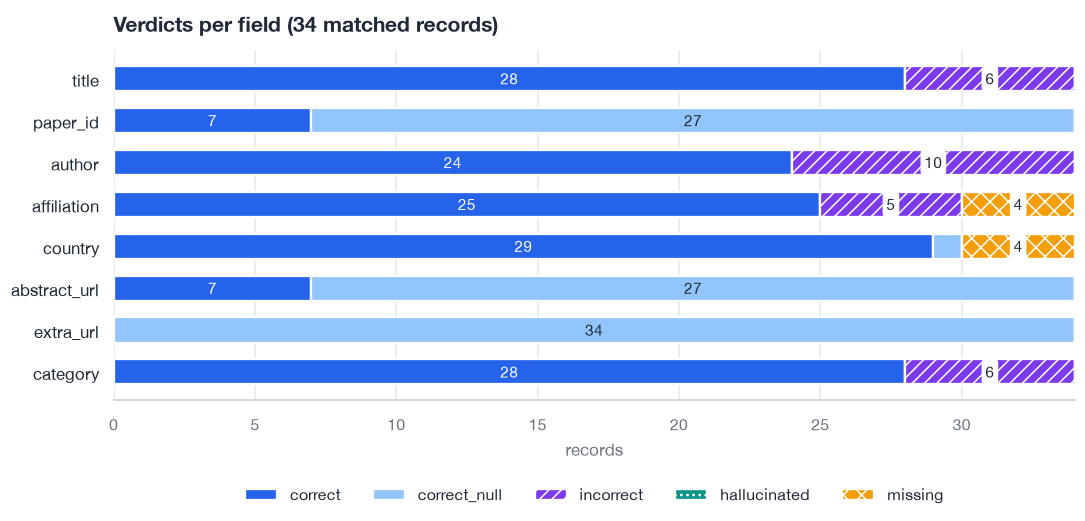

In [7]:
verdicts = {
    "correct": (BLUE, ""),
    "correct_null": (LIGHT, ""),
    "incorrect": ("#7c3aed", "///"),
    "hallucinated": ("#0d9488", "..."),
    "missing": ("#f59e0b", "xx"),
}
vd = pd.DataFrame({k: [fields[f][k] for f in fields] for k in verdicts}, index=list(fields))

fig, ax = plt.subplots(figsize=(10, 5))
left = pd.Series(0, index=vd.index)
for key, (color, hatch) in verdicts.items():
    ax.barh(vd.index, vd[key], left=left, color=color, hatch=hatch, edgecolor="white",
            linewidth=1.5, height=0.6, label=key)
    for y, (l, v) in enumerate(zip(left, vd[key])):
        if v >= 2:
            plain = key in ("correct", "correct_null")
            ax.text(l + v / 2, y, str(v), ha="center", va="center", fontsize=10,
                    color="white" if key == "correct" else INK,
                    bbox=None if plain else dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))
    left += vd[key]
ax.invert_yaxis()
ax.set(xlabel="records", ylabel="", title=f"Verdicts per field ({talks['matched']} matched records)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))

finish(fig, "04_verdicts")

## 5. Misses and fabrications

In [8]:
print(f"Missed ({len(ev['missed_titles'])}):")
for t in ev["missed_titles"]:
    print("  -", t)
print(f"\nFabricated ({len(ev['fabricated_titles'])}):")
for t in ev["fabricated_titles"] or ["(none)"]:
    print("  -", t)

Missed (4):
  - Important roles of selenoproteins and redox biology in cancer
  - Roles of transsulfuration pathway in pancreatic ductal adenocarcinoma
  - Glucocorticoid receptor signaling in breast cancer progression
  - Transcriptome and repertoire profiling of infiltrating γδ T cells to decode tumor escape at single cell resolution

Fabricated (0):
  - (none)
